In [4]:
import os
import random

import numpy as np
import pandas as pd


def seed_everything(seed=42):
    # 1. Base Python randomness
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 2. NumPy randomness
    np.random.seed(seed)
    

# Run the function
seed_everything(42)


# reading data

In [5]:
import logging


class Loader:
    def __init__(self, configs: dict):
        self.configs = configs
        self.combined_df = None
        logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')
        self.logger = logging.getLogger(__name__)

    def _load_single_csv(self, name: str, config: dict) -> pd.DataFrame:
        path = config.get('path')
        columns_map = config.get('columns_map', {})
        label_transform = config.get('label_transform', None)
        
        if not path or not os.path.exists(path):
            self.logger.error(f"File not found or path missing for: {name}")
            return pd.DataFrame()

        try:
            df = pd.read_csv(path, encoding='utf-8')
        except UnicodeDecodeError:
            df = pd.read_csv(path, encoding='latin1')
        except Exception as e:
            self.logger.error(f"Failed to load {name}: {e}")
            return pd.DataFrame()
            
        missing_cols = [col for col in columns_map.keys() if col not in df.columns]
        if missing_cols:
            self.logger.error(f"Missing columns in {name}: {missing_cols}. Found: {list(df.columns)}")
            return pd.DataFrame()
        
        df = df.rename(columns=columns_map)

        if label_transform is not None:
            df['sentiment'] = label_transform(df['sentiment'])

        standard_cols = list(columns_map.values())
        df = df[standard_cols].copy()
    
            
        df['source'] = name 
        
        self.logger.info(f"Loaded '{name}' - Shape: {df.shape}")
        return df

    def load_and_combine(self) -> pd.DataFrame:
        dataframes = []
        
        for name, config in self.configs.items():
            
            df = self._load_single_csv(name, config)
            if df.empty:
                raise ValueError(f"Data reading failed: {name}.")

            dataframes.append(df)

        if not dataframes:
            raise ValueError("No data was successfully loaded.")

        self.logger.info("Concatenating datasets vertically...")
        
        self.combined_df = pd.concat(dataframes, ignore_index=True)
        
        self.logger.info(f"Final combined shape: {self.combined_df.shape}")
        return self.combined_df

## train

In [6]:
def map_label(label_map):
    def mapper(col):
        if pd.api.types.is_string_dtype(col):
            return col.str.lower().map(label_map)
        return col.map(label_map)
    return mapper


In [7]:
HUNDREDK_TRAIN_PATH = "../data/100k_arabic_reviews/train.csv"
TWITTER_TRAIN_PATH = "../data/arabic_twitter/train.csv"
SS230_TRAIN_PATH = "../data/ss2030/train.csv"

training_configs = {
    '100k': {
        'path': HUNDREDK_TRAIN_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({'negative': 0, 'mixed': 1, 'positive': 2})
    },
    
    'twitter': {
        'path': TWITTER_TRAIN_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({'neg': 0, 'pos': 2})
    },
    
    'ss30': {
        'path': SS230_TRAIN_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({0: 0, 1: 2})
    },
}
train_loader = Loader(configs=training_configs)
train_df = train_loader.load_and_combine().sample(frac=1, random_state=42).reset_index(drop=True)

print(f"duplicates={train_df.drop(columns=["source"]).duplicated().sum()}")
print(f"nulls={train_df.drop(columns=["source"]).isna().sum().sum()}")

INFO: Loaded '100k' - Shape: (79999, 3)
INFO: Loaded 'twitter' - Shape: (45273, 3)
INFO: Loaded 'ss30' - Shape: (2551, 3)
INFO: Concatenating datasets vertically...
INFO: Final combined shape: (127823, 3)


duplicates=15737
nulls=0


## validation

In [8]:
HUNDREDK_VAL_PATH = "../data/100k_arabic_reviews/val.csv"
TWITTER_VAL_PATH = "../data/arabic_twitter/val.csv"
SS230_VAL_PATH = "../data/ss2030/val.csv"

val_configs = {
    '100k': {
        'path': HUNDREDK_VAL_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({'negative': 0, 'mixed': 1, 'positive': 2})
    },
    
    'twitter': {
        'path': TWITTER_VAL_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({'neg': 0, 'pos': 2})
    },
    
    'ss30': {
        'path': SS230_VAL_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({0: 0, 1: 2})
    },
}
val_loader = Loader(configs=val_configs)
val_df = val_loader.load_and_combine().sample(frac=1, random_state=42).reset_index(drop=True)

print(f"duplicates={val_df.drop(columns=["source"]).duplicated().sum()}")
print(f"nulls={val_df.drop(columns=["source"]).isna().sum().sum()}")

INFO: Loaded '100k' - Shape: (10000, 3)
INFO: Loaded 'twitter' - Shape: (5759, 3)
INFO: Loaded 'ss30' - Shape: (851, 3)
INFO: Concatenating datasets vertically...
INFO: Final combined shape: (16610, 3)


duplicates=1064
nulls=0


## test

In [9]:
HUNDREDK_TEST_PATH = "../data/100k_arabic_reviews/test.csv"
TWITTER_TEST_PATH = "../data/arabic_twitter/test.csv"
SS230_TEST_PATH = "../data/ss2030/test.csv"

test_configs = {
    '100k': {
        'path': HUNDREDK_TEST_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({'negative': 0, 'mixed': 1, 'positive': 2})
    },
    
    'twitter': {
        'path': TWITTER_TEST_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({'neg': 0, 'pos': 2})
    },
    
    'ss30': {
        'path': SS230_TEST_PATH,
        'columns_map': {'text': 'text', 'sentiment': 'sentiment'},
        'label_transform': map_label({0: 0, 1: 2})
    },
}
test_loader = Loader(configs=test_configs)
test_df = test_loader.load_and_combine().sample(frac=1, random_state=42).reset_index(drop=True)

print(f"duplicates={test_df.drop(columns=["source"]).duplicated().sum()}")
print(f"nulls={test_df.drop(columns=["source"]).isna().sum().sum()}")

INFO: Loaded '100k' - Shape: (10000, 3)
INFO: Loaded 'twitter' - Shape: (5759, 3)
INFO: Loaded 'ss30' - Shape: (850, 3)
INFO: Concatenating datasets vertically...
INFO: Final combined shape: (16609, 3)


duplicates=1030
nulls=0


### class distribution

In [10]:
print((test_df['sentiment'].value_counts(normalize=True) * 100).round(2))


sentiment
2    40.32
0    39.61
1    20.07
Name: proportion, dtype: float64


# preprocess data

In [11]:
import re

import emoji
import nltk
import requests
from camel_tools.utils.charsets import AR_LETTERS_CHARSET
from camel_tools.utils.dediac import dediac_ar
from nltk.stem.isri import ISRIStemmer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer

STOPWORDS_URL = "https://raw.githubusercontent.com/mohataher/arabic-stop-words/master/list.txt"

class TextProcessingPipeline:
    def __init__(self):
        nltk.download('punkt', raise_on_error=True)
        nltk.download('punkt_tab', raise_on_error=True)
        nltk.download('stopwords', quiet=True)
        nltk.download('wordnet', quiet=True)
        
        arabic_letters = ''.join(AR_LETTERS_CHARSET)
        allowed_chars = arabic_letters + '٠١٢٣٤٥٦٧٨٩0123456789' + ' '
        self.clean_regex = re.compile(r'[^' + re.escape(allowed_chars) + r']+')
        
        self.stemmer = ISRIStemmer()
        
        response = requests.get(STOPWORDS_URL)
        self.stopwords = response.text.splitlines()
        

    def __call__(self, text: str) -> str:
        if not isinstance(text, str):
            raise ValueError("text passed to TextProcessingPipeline is not a str")
            
        text = self.clean_arabic_text(text)
        text = self.remove_emoji(text)
        
        text = self.remove_tashkeel(text)
        text = self.remove_tatweel(text)
        
        text = self.normalize_arabic(text)
        
        tokens = self.tokenize(text)
        tokens = self.remove_stopwords(tokens)
        return " ".join(tokens)
    
    def remove_tashkeel(self, text: str) -> str:
        return dediac_ar(text)

    def remove_tatweel(self, text: str) -> str:
        return re.sub(r'\u0640+', '', text)

    def clean_arabic_text(self, text: str) -> str:
        cleaned = self.clean_regex.sub('', text)
        cleaned = ' '.join(cleaned.split())
        return cleaned

    def normalize_arabic(self, text: str) -> str:
        text = re.sub(r"[\u064B-\u0652]", "", text)
        text = re.sub("[إأٱآا]", "ا", text)
        text = re.sub("ى", "ي", text)
        text = re.sub("ؤ", "ء", text)
        text = re.sub("ئ", "ء", text)
        return text

    def remove_emoji(self, text: str) -> str:
        return emoji.replace_emoji(text, replace='')
        
    def tokenize(self, text: str) -> list:
        return word_tokenize(text)
    
    def remove_stopwords(self, tokens: list) -> list:
        return [word for word in tokens if word not in self.stopwords]
    


pipeline = TextProcessingPipeline()
vectorizer = TfidfVectorizer()


/home/yusuf/miniconda3/envs/sentiment/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/yusuf/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package punkt to /home/yusuf/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/yusuf/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [12]:
#____________________train____________________

train_df = train_df.drop_duplicates()
train_df = train_df.dropna()
train_df['cleaned_text'] = train_df['text'].apply(pipeline)

X_train = vectorizer.fit_transform(train_df['cleaned_text'])
y_train = train_df['sentiment'].values

#____________________validation____________________

val_df = val_df.drop_duplicates()
val_df = val_df.dropna()
val_df['cleaned_text'] = val_df['text'].apply(pipeline)

X_val = vectorizer.transform(val_df['cleaned_text'])
y_val = val_df['sentiment'].values

#____________________test____________________

test_df = test_df.drop_duplicates()
test_df = test_df.dropna()
test_df['cleaned_text'] = test_df['text'].apply(pipeline)

X_test = vectorizer.transform(test_df['cleaned_text'])
y_test = test_df['sentiment'].values

              precision    recall  f1-score   support

           0       0.70      0.74      0.72      6080
           1       0.61      0.50      0.55      3333
           2       0.70      0.73      0.72      6133

    accuracy                           0.68     15546
   macro avg       0.67      0.66      0.66     15546
weighted avg       0.68      0.68      0.68     15546



<Axes: >

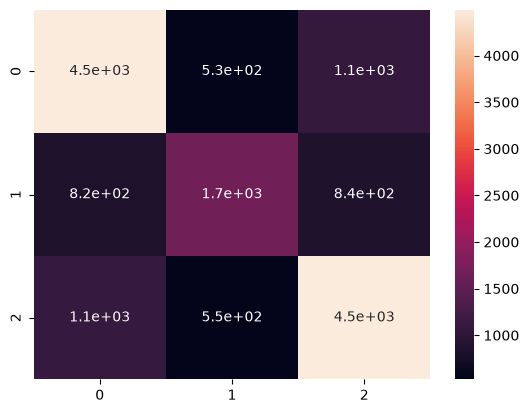

In [13]:
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

model = LogisticRegression(max_iter=1000) 
model.fit(X_train, y_train)

y_pred = model.predict(X_val)

# 5. Generate and print the classification report
# You can use 'target_names' to give your classes human-readable labels
report = classification_report(y_val, y_pred)
print(report)

sns.heatmap(confusion_matrix(y_val, y_pred), annot = True)

In [14]:
import pickle

with open("../models/baseline.pkl", "wb") as file:
    pickle.dump(model, file)


In [15]:
%load_ext watermark
%watermark --iversions


camel_tools: 1.6.0
emoji      : 2.16.0
logging    : 0.5.1.2
matplotlib : 3.11.2
nltk       : 3.10.3
numpy      : 2.5.3
pandas     : 3.0.6
re         : 2.2.1
requests   : 2.34.2
seaborn    : 0.13.2
sklearn    : 1.9.1



In [20]:
np.asarray(X_train[0].toarray()).shape

(1, 290572)